# Methoden en Technieken -- Blok 1

## Datapunt Opdracht

In deze opdracht worden de volgende leeruitkomsten getoetst, relevante termen zijn **dik** gedrukt:
- A2: Je stelt voor een AI-oplossing juridische, ethische, organisatorische, **functionele en
technische requirements** op.
- B1: Je **verkent en prepareert een dataset voor het trainen en testen van een AI-model** en
kan de voor- en nadelen van het gebruik van een bestaande dataset onderbouwen, rekening
houdend met technische en ethische randvoorwaarden.
- B2: Je **stelt op basis van requirements en data een geschikte architectuur voor een AI-
oplossing op en selecteert daarvoor passende AI-technieken gebruik makend van bijvoorbeeld
machine learning, deep learning**, kennisrepresentatie, computer vision en natural language
processing.
- B3: Je **ontwikkelt een nieuw** of voorgetraind **AI-model** volgens een iteratief en systematisch
proces.
- C2: **Je evalueert en beoordeelt de kwaliteit van een AI-model aan de hand van kwaliteitscriteria die in het vakgebied erkend worden** zoals robustness, **performance**, scalability,
explainability, **model complexity** en resource demand.


<hr>

- Dit is een individuele opdracht. Het is toegestaan met elkaar de opdracht te bespreken, maar iedereen schrijft zijn/haar eigen code en antwoorden. 
- Mocht je code van het internet hebben overgenomen/aangepast, vermeld dan de bron in het commentaar.
- Mocht je naar een bron verwijzen voor jouw argumentatie, vermeld dan de bron *en* copy-paste de specifieke uitspraak uit de bron waar je het argument op baseert. 
- Het gebruik van generatieve AI (Chat-GPT, etc...) is *alleen* toegestaan bij de voorbereiding op de opdracht. Denk hierbij aan activiteiten zoals brainstormen, of het maken van een plan. Het is niet toegestaan code of tekst van generative AI over te nemen. (Level 2 van de AI Assessment Scale)


Dit volgende code leest de data in, het bestand **Visegrad2020.csv** is samen met deze opdracht te vinden op DLO.

In [1]:
%pip install plotly
%pip install sklearn
%pip install scikit-learn imbalanced-learn
%pip install "nbformat>=5.0"
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.
  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [45]:
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from IPython.display import display
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

data = pd.read_csv('Visegrad2020.csv', index_col=0)

In deze opdracht ga je een model maken om de sector (kolom $S$, 6 klassen) te voorspellen a.d.h.v. de verklarende variabelen $X_1$ t/m $X_{82}$. Doel is hier niet om een interpreteerbaar model te maken, maar mocht je geïnteresseerd zijn in de herkomst van de data en de betekenis van de variabelen dan is dit te vinden op [https://archive.ics.uci.edu/dataset/830/visegrad+group+companies+data-2](https://archive.ics.uci.edu/dataset/830/visegrad+group+companies+data-2).

Het doel van deze opdracht is niet zo zeer om een zo goed mogelijk model op te leveren, maar om te laten zien dat je al jouw keuzes in de modellering en evaluatie kan toelichten, verantwoorden, en correct kan toepassen.
### De opdracht

# Deel A

Verken de data, en voer eventuele datapreparatie uit, leg kort uit wat je opvalt.

Ik ben benieuwd naar de afmetingen van de dataset. met deze informatie kunnen we keuzes maken over hoe we de data willen splitten in train en test sets. Willen we dit strettified of random doen? Hoeveel data hebben we eigenlijk?
Veel data zal de keuze voor random split onderbouwen, maar weinig data zal de keuze voor een stratified split onderbouwen.

In [3]:
print("Afmetingen van de dataset:")
print(data.shape)
print("===================================")
print("Kolomnamen van de dataset:")
print(data.columns.tolist())


Afmetingen van de dataset:
(133, 83)
Kolomnamen van de dataset:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29', 'X30', 'X31', 'X32', 'X33', 'X34', 'X35', 'X36', 'X37', 'X38', 'X39', 'X40', 'X41', 'X42', 'X43', 'X44', 'X45', 'X46', 'X47', 'X48', 'X49', 'X50', 'X51', 'X52', 'X53', 'X54', 'X55', 'X56', 'X57', 'X58', 'X59', 'X60', 'X61', 'X62', 'X63', 'X64', 'X65', 'X66', 'X67', 'X68', 'X69', 'X70', 'X71', 'X72', 'X73', 'X74', 'X75', 'X76', 'X77', 'X78', 'X79', 'X80', 'X81', 'X82', 'S']


We zien dat er niet veel rijen in de dataset zitten. We hebben 133 rijen en 83 kolommen. De 83ste kolom is de target variabele.
Dit is niet veel data, dus we zullen een stratified split moeten doen om ervoor te zorgen dat de verdeling van de klassen in de train en test sets gelijk is. 

In [4]:
X = data.drop(columns=['S'])
y = data['S']

# Bron van de syntax die ik heb gevonden en aangepast en de regel: (link - https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html ), regel - X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.33, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42, #standaard randome state in de ML wereld.
    stratify=y
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(106, 82)
(27, 82)
(106,)
(27,)


Ik heb voor testsize 0.2 gekozen omdat we niet veel data hebben en we willen zoveel mogelijk data gebruiken om het model te trainen. 
De verdeling van de klassen in de train en test sets moet gelijk zijn. Dit is alleen moeilijk te bepalen zonder dataleakage lijkt me. Het kan dan zijn dat sommige categorien onder gerepresenteerd zijn dus dan is een hogere testsize beter. Maar we hebben niet veel data dus we willen zoveel mogelijk data gebruiken om het model te trainen.

nu we hebben gesplitst, ik ben benieuw wat de verdeling is van de target S categorien. 

In [5]:
#nu we hebben gesplitst, ik ben benieuw wat de verdeling is van de target S categorien. 

# print het aantal observaties per categorie
print("Aantal observaties per categorie in de train dataset:")
print(y_train.value_counts())

Aantal observaties per categorie in de train dataset:
S
3    53
2    17
6    16
4    15
1     3
5     2
Name: count, dtype: int64


In [6]:
# We zetten ze nog even op volgorde van categorie 1 naar 6
categorie_counts = y_train.value_counts().sort_index()

# Maak mooi interactief plotje met plotly (import bij de rest van me imports gezet) 
# Visualiseer de verdeling van S
fig = px.bar(
    x=categorie_counts.index.astype(str),
    y=categorie_counts.values,
    labels={
        'x': 'categorie (S)',
        'y': 'Aantal in trainset'
    },
    title='Verdeling van S categorieën in trainingsset',
    text=categorie_counts.values
)

fig.show()
# Eerste observatie en gevoel: Wat een rot dataset. De verdeling van de targetcategorieën is niet gelijk. Er zijn veel meer observaties in categorie 3 dan in categorie 1 of 5. Dit kan een probleem zijn voor het trainen van een model.
# Er zijn twee belangrijke gevolgen die ik me nu kan bedenken voor als een model gekozen moet gaan worden. 1 = het model kan geneigd zijn vooral categorie 3 te voorspellen, omdat deze de helft van de trainingsdata vertegenwoordigt.Dit kan leiden tot een hoge accuracy, maar een lage F1-score voor de andere categorieën. 2 = het model kan moeite hebben met het leren van de minder vertegenwoordigde categorieën, wat kan leiden tot een lage recall voor deze categorieën.
# Macro F1-score en een confusion matrix kunnen later helpen om de prestaties per klasse te beoordelen.

Eerste observatie en gevoel: Wat een rot dataset. De verdeling van de targetcategorieën is duidelijk niet gelijk. Er zijn veel meer observaties in categorie 3 dan in categorie 1 of 5. Dit kan een probleem zijn voor het trainen van een model.

Er zijn twee belangrijke gevolgen die ik me nu kan bedenken voor als een model gekozen moet gaan worden. 1 = het model kan geneigd zijn vooral categorie 3 te voorspellen, omdat deze de helft van de trainingsdata vertegenwoordigt.Dit kan leiden tot een hoge accuracy, maar een lage F1-score voor de andere categorieën. 2 = het model kan moeite hebben met het leren van de minder vertegenwoordigde categorieën, wat kan leiden tot een lage recall voor deze categorieën.

Ik wil daarom niet alleen naar accuracy kijken, maar vooral naar de F1-score. Bij verder onderzoek naar verschillende manieren om de F1-score te middelen, ben ik uitgekomen op macro F1 en weighted F1. Bij weighted F1 telt de F1-score van iedere categorie mee op basis van het aantal observaties in die categorie. Categorie 3 krijgt daardoor veel meer invloed op de eindscore dan categorie 1 en 5. Dat vind ik voor deze dataset minder handig, omdat ik juist wil voorkomen dat goede prestaties op categorie 3 de slechte prestaties op de kleine categorieën oversneeuwen/overschaduwen.

bron: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html

regels: parameter average : ctrl+F - "Calculate metrics for each label"

De volgende dingen die ik nu wil controleren zijn de volgende gegevens van de X-train data. Met deze inzichten kan ik nog wat datapreparatie doen of inzichten verzamelen die mijn keuze voor een model zullen bepalen.

-   Datatypes (Zijn de 82 features nummeriek of hebben we nog andere categorien in de dataset zitten)
-   Nan en 0 waarden natuurlijk (Hoeveel NaN-waarden of 0 zijn er en in welke kolommen)
-   Statistische verdelingen bekijken (Zijn er grote verschillen in schaal van variable? zitten er gekke uitschieters tussen of variable  met nauwelijks variatie?
-   Correlaties tussen verschillende variable bekijken (correlatiematrixie)

In [7]:
#Datatype analyse
print("Datatypes van de features:")
print(X_train.dtypes.value_counts())
print(X_train.head(10))

# NaN/0 analyse
# Controleer voor ontbrekende waarden in de dataset
missing_values = X_train.isna().sum()

print("Totaal aantal ontbrekende waarden:")
print(missing_values.sum())
print("==================================")
print("Ontbrekende waarden per feature:")
print(missing_values[missing_values > 0])

print("==================================================================")
print("==================================================================")


zero_values = (X_train == 0).sum()

print("Totaal aantal nulwaarden:")
print(zero_values.sum())
print("==================================")
print("Nulwaarden per feature:")
print(zero_values[zero_values > 0])

# Nulwaarden per observatie
zeros_per_row = (X_train == 0).sum(axis=1)

print("Observaties met de meeste nulwaarden:")
print(zeros_per_row.sort_values(ascending=False).head(10))
# inzoomen op de zes opvallende observaties en het checken of ze gemen=enschappelijk patroon hebben
selected_ids = [310, 7, 203, 449, 352, 407]

# Vergelijken de nulpatronen
zero_patterns = X_train.loc[selected_ids] == 0

# Controleer of alle nulpatronen toevallig het zelfde zijn
print(zero_patterns.eq(zero_patterns.iloc[0]).all().all())
print(y_train.loc[selected_ids])

Datatypes van de features:
float64    82
Name: count, dtype: int64
       X1    X2    X3    X4    X5    X6    X7    X8    X9   X10  ...   X73  \
ID                                                               ...         
303  0.19  1.44 -0.81  0.38 -8.96  0.20 -0.30  8.37 -0.44  0.25  ...  0.29   
71   0.06  0.33  0.27  1.85  0.04  0.11  2.17  1.03  0.72  0.09  ...  1.32   
342  0.13  0.55  0.46  2.14  0.13  0.16  0.81  1.99  0.45  0.18  ...  1.10   
402 -0.40  0.95  0.16  1.23 -1.06 -0.43  0.06  0.91  0.06 -0.40  ...  0.56   
262  0.12  0.26  0.48  3.68  0.15  0.17  2.80  0.67  0.74  0.15  ...  1.35   
16  -0.02  0.70  0.05  1.13 -0.02 -0.01  0.42  0.73  0.30  0.02  ...  0.92   
179  0.06  0.49 -0.10  0.61  0.30  0.08  1.05  0.13  0.51  0.12  ...  0.92   
388 -0.06  0.80 -0.17  0.47 -0.07 -0.06  0.25  0.18  0.20 -0.05  ...  0.30   
425 -0.09  0.54  0.13  1.54 -0.10 -0.09  0.83  0.10  0.45 -0.08  ...  0.55   
352  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  ...  0.00 

We kunnen nu al zien dat categorie 5 een probleem kan worden. Er zijn maar twee observaties in deze categorie en één daarvan bevat 73 nulwaarden. Ik vraag me af of het model met zo weinig voorbeelden überhaupt genoeg informatie heeft om deze categorie goed te leren herkennen.

Daarnaast hebben meerdere observaties precies hetzelfde nulpatroon, maar behoren ze niet allemaal tot dezelfde categorie. We kunnen dus voorzichtig zeggen dat dit nulpatroon op zichzelf niet voldoende is om de S-waarde te voorspellen. Misschien heeft categorie 5 een speciale betekenis, bijvoorbeeld als een soort restcategorie voor waarnemingens die niet goed in andere categorieën passen. Maar dat weten we nog niet! Ook weet ik niet wat de nulwaarden precies betekenen, dus ik ga ze voorlopig niet verwijderen of vervangen. 


Nu wil ik kijken hoe de waarden van de voorspellende features verdeeld zijn. hebben ze  grote verschillen in schaal, of zijn er opvallende uitschieters waar we iets mee moeten doen?

Ik heb hieronder een boxplot grafiek gemaakt om te zien welke variablen vooral ook een andere schaal hebben. Dit zal mijn keuze bepalen of de data meschien geschaald of genormaliseerd moet worden. 

In [8]:
fig = px.box(
    X_train,
    title="Verdeling van de features vóór standaardisatie"
)

fig.update_layout(
    xaxis_title="Features",
    yaxis_title="Waarde",
)

fig.show()


# Maak de scaler aan die we willen gaan gebruiken. indit geval gaan we voor de StandardScaler, omdat we de data willen standaardiseren naar een gemiddelde van 0 en een standaarddeviatie van 1. Zo kunnen we de verdeling van de waarden per feature beter vergelijken en kan later eventueel het model beter leren van de data.
# bron: https://scikit-learn.org/stable/modules/preprocessing.html regel: het eerste stukje voorbeeldcode op de pagina
scaler = StandardScaler()

# Bereken de parameters uitsluitend op de trainingsdata door fit_transform te gebruiken. Dit is belangrijk om dataleakage te voorkomen. We willen niet dat de testdata invloed heeft op de schaling van de trainingsdata.
X_train_scaled = scaler.fit_transform(X_train)

# Pas dezelfde transformatie toe op de testdata, nu zonder fit_transform.
X_test_scaled = scaler.transform(X_test)
fig = px.box(
    X_train_scaled,
    title="Verdeling van de features na standaardisatie"
)

fig.update_layout(
    xaxis_title="Features",
    yaxis_title="Gestandaardiseerde waarde"
)

fig.show()



Wat meteen opvalt voor standaardisatie, is dat er grote verschillen zitten in de waarden en spreiding van de features. Een paar features hebben ook enorme uitschieters, waardoor de verdeling van de meeste andere features nauwelijks zichtbaar is.

Ik weet niet wat de features precies voorstellen. Daarom kan ik niet aannemen dat deze uitschieters foutief zijn en ga ik ze voorlopig niet verwijderen of aanpassen.

De verschillen in schaal zijn wel iets om rekening mee te houden bij mijn modelkeuze. Sommige modellen zijn hier gevoelig voor en kunnen daarom baat hebben bij standaardisatie. Ik wil de data dus nog niet zomaar schalen en gebruiken voor mijn model, maar eerst onderzoeken welk model geschikt is. Als ik voor een schaalgevoelig model kies, kan ik standaardisatie meenemen in de preprocessing.

Ook moet ik rekening houden met de uitschieters, omdat de `StandardScaler` hier gevoelig voor is. Of deze scaler geschikt is, wil ik daarom pas bepalen wanneer ik mijn modelkeuze verder heb onderbouwd.

Voor nu geeft het in elk geval inzicht in de verdeling van elke feauter en hebben we weer meer informatie voor latere modelkeuze


Eerst wil ik nog kijken naar de correlaties tussen de features. Misschien zijn er variabelen die sterk met elkaar samenhangen en grotendeels dezelfde informatie bevatten. Dit kan ik vervolgens meenemen bij mijn modelkeuze.


In [9]:
# Voeg de doelvariabele S toe aan de trainingsfeatures
train_corrie = X_train.copy()

# Bereken de correlatiematrix
corr_matrix = train_corrie.corr()

# Visualiseer de correlatiematrix
fig = px.imshow(
    corr_matrix,
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Correlatiematrix van de trainingsfeatures"
)

fig.update_layout(
    width=1100,
    height=1000,
    xaxis_title="Features en doelvariabele",
    yaxis_title="Features en doelvariabele"
)

fig.show()
import numpy as np
# Toon de sterkste correlaties tussen verschillende features
corr_pairs = corr_matrix.where(
    ~np.eye(len(corr_matrix), dtype=bool)
).stack()

print(corr_pairs.abs().sort_values(ascending=False).head(20))

X43  X23    0.999801
X23  X43    0.999801
X42  X43    0.999680
X43  X42    0.999680
X23  X42    0.999670
X42  X23    0.999670
X8   X30    0.999426
X30  X8     0.999426
X69  X68    0.999006
X68  X69    0.999006
     X70    0.997471
X70  X68    0.997471
X20  X5     0.997215
X5   X20    0.997215
X67  X69    0.996976
X69  X67    0.996976
X70  X69    0.996154
X69  X70    0.996154
X68  X67    0.995366
X67  X68    0.995366
dtype: float64


Sommige features hebben bijna een perfecte correlatie met elkaar. X23 en X43 hebben correlatie van bijna 100 (0,9998) Wat absurt hoog is. Ook X42 hangt heel sterk samen met deze twee features. Daarnaast zie ik een groep rondom X66 t/m X71 die ook sterk met elkaar correleren.

Ik denk dat deze featers grotendeels de zelfde informatie bevatten. Ik weet alleen niet wat die informatie is dus kan voorderest ook weinig met deze bevinding zeggen. 

Ik ga voorlopig geen features verwijderen en ik neem deze sterke correlaties van meerdre feauters mee als aandachtspunt voor mijn keuze van mijn model, een die niet gevoelig is als er meerdere sterk samenhangende faeters zijn bijvoorbeeld.


### Samenvatting van mijn waarnemingen

* **Kleine dataset:** Ik heb 133 observaties, 82 features en één targetvariabele. Daarom heb ik gekozen voor een gestratificeerde train-testverdeling van 80/20, zodat de klasseverhoudingen zo goed mogelijk behouden blijven.

* **Ongelijke klasseverdeling:** In mijn trainingsset zitten 53 observaties in categorie 3, maar slechts 3 in categorie 1 en 2 in categorie 5. Ik verwacht dat vooral het herkennen van deze kleine categorieën lastig kan worden. Daarom wil ik mijn modellen beoordelen met de macro F1-score.

* **Datatypes en ontbrekende waarden:** Alle 82 features zijn numeriek (`float64`). Er zijn geen ontbrekende waarden, dus ik hoef hiervoor geen datapreparatie uit te voeren.

* **Veel nulwaarden:** Ik tel 1.037 nulwaarden. Zeven observaties bevatten elk 73 nulwaarden. Sommige observaties hebben hetzelfde nulpatroon, maar behoren tot verschillende categorieën. Het nulpatroon alleen is dus niet voldoende om de categorie te bepalen. Omdat ik niet weet wat de nulwaarden betekenen, laat ik ze voorlopig staan.

* **Verschillen in schaal:** In de eerste boxplot zie ik dat de features sterk verschillen in schaal. Enkele zeer grote waarden maken de verdeling van de meeste andere features nauwelijks zichtbaar.

* **Effect van standaardisatie:** In de tweede boxplot zijn de features beter met elkaar te vergelijken. De waarden liggen grotendeels rond nul, maar er zijn nog steeds duidelijke uitschieters. Standaardisatie verwijdert uitschieters dus niet. Ik bepaal pas bij mijn modelkeuze of ik deze preprocessing daadwerkelijk ga gebruiken.

* **Sterke correlaties:** Sommige features hangen bijna perfect met elkaar samen. Zo is de correlatie tussen X23 en X43 ongeveer 0,9998. Mogelijk bevatten deze features grotendeels dezelfde informatie. Omdat ik niet weet wat ze voorstellen, verwijder ik voorlopig geen features.

**Conclusie:** Ik ga voor mijn modelkeuze vooral rekening houden met de kleine dataset, de ongelijke klasseverdeling, de schaalverschillen, de uitschieters en de sterke correlaties. Ik verwijder of vervang op dit moment geen gegevens, omdat ik onvoldoende weet over de betekenis van de features.



# Deel B

We gaan door naar het onderdeel: Modelkeuze. Hierin wil ik een baseline model kiezen en bedenken wat mijn prestatie maat gaat worden. 
eerder hebbem we al bedacht dat accuracy niet helemaal eerlijk de prestatie weergeeft omdat de dataset zo ongebalanceerd is

Ik kies een DummyClassifier met de strategie most_frequent. Dit model voorspelt altijd de meest voorkomende categorie, in mijn trainingsset categorie 3. Hiermee creëer ik een eenvoudige referentie om mijn andere modellen mee te vergelijken. 

bron: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html, 

regel: ctrl+F - "This classifier serves as a simple baseline" .

Ik heb opgezocht welke prestatiemaat het best te gebruiken is voor een sterk ongebalanceerde dataset en kwm uit op een F1-score. 

bron: https://www.everpuredata.com/nl/knowledge/machine-learning-performance-metrics.html 

regel: De F1-score is het harmonische gemiddelde van ... .

Daarna ben ik me verder gaan verdiepen in soorten F1-scores en heb ik gekozen voor de macro F1-score. Bij de macro F1-score wordt de F1-score per categorie berekend en vervolgens ongewogen gemiddeld. Hierdoor tellen alle zes categorieen even zwaar mee. Door alle zes categorien even zwaar mee te nemen, beoordeel ik of mijn model over de verschillende categorieen heen goed presteert, in plaats van voornamelijk op categorie 3.

Ik heb ook gekeken naar de weighted F1-score, omdat deze rekening houdt met de ongelijke klasseverdeling. Bij weighted F1 wordt de F1-score van iedere categorie echter gewogen op basis van het aantal observaties in die categorie. Hierdoor heeft categorie 3 veel meer invloed op de eindscore dan categorie 1 en 5.

Dat wil ik juist voorkomen. Ik wil namelijk ook kunnen beoordelen of mijn model de categorieën met weinig observaties goed herkent. Daarom kies ik voor macro F1 als mijn belangrijkste prestatie maat.

Bron: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html 

regel: f1_score — scikit-learn, bij average='macro': “Calculate metrics for each label, and find their unweighted mean.”

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score

# Nulmodel aanmaken en trainen
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

# Voorspellingen op de trainingsdata
y_pred_dummy = dummy.predict(X_train)

# Prestatiematen berekenen
f1_macro = f1_score(
    y_train, y_pred_dummy,
    average="macro",
    zero_division=0
)

f1_weighted = f1_score(
    y_train, y_pred_dummy,
    average="weighted",
    zero_division=0
)

accuracy = accuracy_score(y_train, y_pred_dummy)



resultaten = pd.DataFrame({
    "Prestatiemaat": ["Macro F1-score", "Weighted F1-score", "Accuracy"],
    "Score": [f1_macro, f1_weighted, accuracy]
})

display(
    resultaten.style
    .format({"Score": "{:.3f}"})
    .hide(axis="index")
    .apply(
        lambda row: ["font-weight: bold"] * len(row)
        if row["Prestatiemaat"] == "Macro F1-score"
        else [""] * len(row),
        axis=1
    )
)

Prestatiemaat,Score
Macro F1-score,0.111
Weighted F1-score,0.333
Accuracy,0.500


# Deel C

Stel, onder andere aan de hand van jouw antwoorden in deel A en B, een korte lijst van *requirements* op. Waar moet je model minimaal aan voldoen. Licht gemaakte keuzes kort en bondig toe.

## Requirements voor mijn model

Op basis van mijn dataverkenning en het nulmodel stel ik de volgende requirements op:

* **Beter presteren dan het nulmodel:** Mijn model moet een hogere macro F1-score behalen dan de `DummyClassifier`. Anders heeft het model geen aantoonbare meerwaarde ten opzichte van het altijd voorspellen van categorie 3.

* **Rekening houden met de ongelijke klasseverdeling:** Het model moet niet alleen categorie 3 goed voorspellen, maar ook proberen de kleinere categorieën te herkennen. Daarom gebruik ik macro F1 als belangrijkste prestatiemaat en bekijk ik daarnaast de resultaten per categorie.

* **Geschikt zijn voor weinig observaties en veel features:** Ik heb slechts 106 trainingsobservaties tegenover 82 features. Ik wil daarom een model kiezen dat met deze beperkte hoeveelheid data kan worden getraind, zonder onnodig complex te zijn.

* **Kunnen omgaan met sterk samenhangende features:** Sommige features correleren bijna perfect. Ik wil een model kiezen waarbij ik rekening kan houden met deze samenhang, zonder vooraf zomaar features te verwijderen.

* **Zorgvuldig omgaan met schaalverschillen en uitschieters:** De features verschillen sterk in schaal en bevatten opvallende uitschieters. Bij mijn modelkeuze moet ik daarom onderzoeken of standaardisatie nodig en geschikt is.

* **Geen datalekken veroorzaken:** Eventuele preprocessing en modelkeuzes moeten uitsluitend op de trainingsdata worden bepaald. De testset bewaar ik voor de uiteindelijke evaluatie.




# Deel D

Op basis van mijn dataverkenning wil ik twee modellen onderzoeken: Logistic Regression en Random Forest. Ik kies bewust twee verschillende modellen, zodat ik kan vergelijken hoe een lineair model en een model op basis van beslisbomen omgaan met de eigenschappen van mijn dataset.

**1. Logistische regressie**
Deze lijkt mij interessant omdat ik weinig trainingsobservaties heb tegenover relatief veel features. Ik wil daarom beginnen met een model waarvan ik de complexiteit kan beperken door de regularisatie variable te tweaken.

bron: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

regel: "This class implements regularized logistic..."

Daarnaast ondersteunt Logistic Regression classificatie met meerdere categorieën en kan ik met class_weight="balanced" onderzoeken of het helpt om de kleine categorieën zwaarder mee te wegen. 

Bron: LogisticRegression — scikit-learn. Zie de beschrijving “Logistic Regression (aka logit, MaxEnt) classifier”, de parameter C (“Inverse of regularization strength”) en de parameter class_weight, waarin staat dat "balanced" gewichten gebruikt die omgekeerd evenredig zijn aan de klassefrequenties.

Een aandachtspunt is dat mijn features sterk verschillen in schaal. Daarom wil ik bij logistische regressie standaardisatie toepassen. Ik wil hiervoor beginnen met StandardScaler, die de features schaalt naar een gemiddelde van 0 en een standaarddeviatie van 1. 

bron: https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html
regel: "First we show how the optimal regularization..."

In Deel A zag ik echter ook grote uitschieters. Omdat StandardScaler gevoelig is voor uitschieters, wil ik eventueel ook RobustScaler onderzoeken. Deze gebruikt de mediaan en het interkwartielbereik en is daardoor minder gevoelig voor extreme waarden.

Ik ga de uitschieters voorlopig niet verwijderen, omdat ik niet weet wat de features precies betekenen. Met cross-validation wil ik onderzoeken welke manier van schalen beter werkt voor mijn model.

bron: 

**2. Random Forest**
Random Forest lijkt mij interessant als tweede model omdat het op een andere manier werkt dan logistische regressie. Het combineert meerdere beslisbomen en kan ook niet-lineaire verbanden leren. Omdat ik niet weet wat mijn 82 features precies voorstellen, weet ik ook niet of hun verband met de target lineair is. Daarom wil ik onderzoeken of Random Forest andere patronen kan herkennen.

In Deel A zag ik grote schaalverschillen en uitschieters. Een voordeel van Random Forest is dat standaardisatie hiervoor niet nodig is. Beslisbomen maken splitsingen op basis van grenswaarden binnen afzonderlijke features. Het maakt voor zo'n splitsing in principe niet uit of een feature in kleine of grote getallen wordt uitgedrukt, zolang de volgorde van de waarden gelijk blijft. Daarom ga ik bij Random Forest geen StandardScaler of RobustScaler toepassen.

Ook hier is er weer een aandachtspunt waar op gelet moet worden. Beslisbomen kunnen erg specifiek worden voor de trainingsdata. Daarom wil ik de complexiteit beperken door de maximale diepte (max_depth) en het minimale aantal observaties per blad (min_samples_leaf) te onderzoeken.

Tot slot wil ik, net als bij logistische regressie, class_weight="balanced" vergelijken met None. Hiermee kan ik onderzoeken of het zwaarder meewegen van de kleine categorieën helpt om mijn macro F1-score te verbeteren.

brond: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

regel: max_depth, min_samples_leaf en class_weight

bron: https://scikit-learn.org/stable/modules/tree.html

regel: "Decision trees tend to..."


# 3. Hyperparameter
Ik wil de hyperparameters met een beperkte GridSearchCV onderzoeken. Hiermee kan ik vooraf een aantal waarden vastleggen en de combinaties systematisch vergelijken. Ik gebruik voor beide modellen de macro F1-score als belangrijkste prestatiemaat.

bron: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html 

regel: “Exhaustive search over specified parameter values for an estimator”.

Voor Logistic Regression wil ik de volgende instellingen onderzoeken:

- C = [0.01, 0.1, 1, 10]: hiermee onderzoek ik de invloed van de regularisatiesterkte. Een kleinere C betekent sterkere regularisatie.
- class_weight = [None, "balanced"]: hiermee onderzoek ik of het meewegen van de kleine categorieën helpt.
- StandardScaler en RobustScaler: hiermee onderzoek ik welke manier van schalen geschikt is voor mijn data met grote schaalverschillen en uitschieters.

Voor Random Forest wil ik de volgende instellingen onderzoeken:

- max_depth = [3, 5, None]: hiermee onderzoek ik de invloed van de maximale boomdiepte.
- min_samples_leaf = [1, 2, 5]: hiermee onderzoek ik of een minimumaantal observaties per eindknoop helpt om de bomen minder specifiek te maken.
- class_weight = [None, "balanced"]: hiermee onderzoek ik of het meewegen van de kleine categorieën helpt.

Omdat categorie 5 slechts twee observaties in de trainingsset bevat, gebruik ik gestratificeerde cross-validation met twee folds.Dit zodat er 1 waarde van categorie 5 in elke fold zit. Ik gebruik dezelfde folds op de 3 modellen en ga ze dan vergelijken.

bron: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html 

regel: “The folds are made by preserving the percentage of samples for each class ... ”.

ik ga dit ook allemaal doen door dingen in pipelines te zetten (tip van Rik) om geordend te werken en eventuele gevaren voor dataleakige te voorkomen.

bron: https://scikit-learn.org/stable/common_pitfalls.html 

regel: “Alternatively, we recommend using a Pipeline ...”.

# Deel E & F
ik ga de 2 gekozen modellen nu trainen en ook meteen mijn volgende itteratie erover doen. zo hou ik de beste macro-f1 score over voor beide modellen en mijn dummy model over, Ik kan dan de uitkomsten naast elkaar leggen en evalueren op mijn requirements.

In [11]:
cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=10
)

**Logistic Regression**

We zetten de scaler en het model in één pipeline. Via GridSearchCV vergelijken we de twee eerder genoemde scalers, vier overzicht gevende waarden voor C en twee opties voor class_weight.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Pipeline: eerst schalen, daarna classificeren
pipeline_logR = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=10
    ))
])

# Hyperparameters uit Deel D
param_grid_logR = {
    "scaler": [
        StandardScaler(),
        RobustScaler()
    ],
    "model__C": [0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000],
    "model__class_weight": [None, "balanced"]
}

# Zoek de combinatie met de hoogste gemiddelde macro F1
grid_logR = GridSearchCV(
    estimator=pipeline_logR,
    param_grid=param_grid_logR,
    scoring="f1_macro",
    cv=cv,
    refit=True,
    n_jobs=-1
)

grid_logR.fit(X_train, y_train)

print("Beste hyperparameters Logistic Regression:")
print(grid_logR.best_params_)
print("===============================")
print(f"Beste gemiddelde macro F1: {grid_logR.best_score_:.3f}")

# Haal de resultaten van GridSearchCV op
cv_results_logR = pd.DataFrame(grid_logR.cv_results_)

# Maak de scaler-namen leesbaar
cv_results_logR["Scaler"] = cv_results_logR["param_scaler"].apply(
    lambda scaler: type(scaler).__name__
)

# Maak de class_weight-namen leesbaar
cv_results_logR["Class weight"] = cv_results_logR["param_model__class_weight"].apply(
    lambda weight: str(weight)
)

# Zet C om naar numerieke waarden voor de x-as
cv_results_logR["C"] = cv_results_logR["param_model__C"].astype(float)

# Plot de gemiddelde macro F1-score per hyperparametercombinatie
fig = px.line(
    cv_results_logR,
    x="C",
    y="mean_test_score",
    color="Scaler",
    line_dash="Class weight",
    markers=True,
    log_x=True,
    title="Hyperparameteronderzoek Logistic Regression",
    labels={
        "C": "Regularisatieparameter C",
        "mean_test_score": "Gemiddelde macro F1-score"
    }
)

fig.show()

Beste hyperparameters Logistic Regression:
{'model__C': 1000, 'model__class_weight': 'balanced', 'scaler': RobustScaler()}
Beste gemiddelde macro F1: 0.289


er zijn 2 pieken te zien waar we op willen inzoomen en de C waarden willen verfijnen. tussen C = 0.1 & 10 en tussen C = 100 & 10000. We gaan hier dus op inzoomen

In [32]:
# Eerste zoom: verfijning van de C-waarden
param_grid_logR_zoom = {
    "scaler": [
        StandardScaler(),
        RobustScaler()
    ],
    "model__C": [
        0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5, 7, 10,
        100, 120, 150, 200, 300, 500, 700, 1000,
        1500, 2000, 3000, 5000, 7000, 10000
    ],
    "model__class_weight": [None, "balanced"]
}

# Zoek de combinatie met de hoogste gemiddelde macro F1
grid_logR_zoom = GridSearchCV(
    estimator=pipeline_logR,
    param_grid=param_grid_logR_zoom,
    scoring="f1_macro",
    cv=cv,
    refit=True,
    n_jobs=-1
)

grid_logR_zoom.fit(X_train, y_train)

print("Beste hyperparameters eerste zoom:")
print(grid_logR_zoom.best_params_)
print("===============================")
print(f"Beste gemiddelde macro F1: {grid_logR_zoom.best_score_:.3f}")


# Haal de resultaten van de eerste zoom op
cv_results_logR_zoom = pd.DataFrame(grid_logR_zoom.cv_results_)

# Maak de scaler-namen leesbaar
cv_results_logR_zoom["Scaler"] = cv_results_logR_zoom["param_scaler"].apply(
    lambda scaler: type(scaler).__name__
)

# Maak de class_weight-namen leesbaar
cv_results_logR_zoom["Class weight"] = cv_results_logR_zoom[
    "param_model__class_weight"
].apply(lambda weight: str(weight))

# Zet C om naar numerieke waarden voor de x-as
cv_results_logR_zoom["C"] = cv_results_logR_zoom[
    "param_model__C"
].astype(float)

# Plot de gemiddelde macro F1-score per hyperparametercombinatie
fig = px.line(
    cv_results_logR_zoom,
    x="C",
    y="mean_test_score",
    color="Scaler",
    line_dash="Class weight",
    markers=True,
    log_x=True,
    title="Eerste zoom Logistic Regression",
    labels={
        "C": "Regularisatieparameter C",
        "mean_test_score": "Gemiddelde macro F1-score"
    }
)

fig.show()

Beste hyperparameters eerste zoom:
{'model__C': 700, 'model__class_weight': None, 'scaler': RobustScaler()}
Beste gemiddelde macro F1: 0.349


Oeehhhhh, interresant. we doen nog een extra zoom op het gebied C = 300 & 5000

In [33]:
# Bewaar het gekozen model uit de eerste zoom
beste_logR = grid_logR_zoom.best_estimator_

print("Gekozen model Logistic Regression:")
print(beste_logR)

Gekozen model Logistic Regression:
Pipeline(steps=[('scaler', RobustScaler()),
                ('model',
                 LogisticRegression(C=700, max_iter=5000, random_state=10))])


In [35]:
# Tweede zoom: onderzoek C van 300 tot en met 5000
param_grid_logR_zoom2 = {
    "scaler": [
        StandardScaler(),
        RobustScaler()
    ],
    "model__C": np.arange(300, 5001, 50).tolist(),
    "model__class_weight": [None, "balanced"]
}

# Zoek de combinatie met de hoogste gemiddelde macro F1
grid_logR_zoom2 = GridSearchCV(
    estimator=pipeline_logR,
    param_grid=param_grid_logR_zoom2,
    scoring="f1_macro",
    cv=cv,
    refit=True,
    n_jobs=-1
)

grid_logR_zoom2.fit(X_train, y_train)

print("Beste hyperparameters tweede zoom:")
print(grid_logR_zoom2.best_params_)
print("===============================")
print(f"Beste gemiddelde macro F1: {grid_logR_zoom2.best_score_:.3f}")


# Haal de resultaten van de tweede zoom op
cv_results_logR_zoom2 = pd.DataFrame(grid_logR_zoom2.cv_results_)

# Maak de scaler-namen leesbaar
cv_results_logR_zoom2["Scaler"] = cv_results_logR_zoom2["param_scaler"].apply(
    lambda scaler: type(scaler).__name__
)

# Maak de class_weight-namen leesbaar
cv_results_logR_zoom2["Class weight"] = cv_results_logR_zoom2[
    "param_model__class_weight"
].apply(lambda weight: str(weight))

# Zet C om naar numerieke waarden voor de x-as
cv_results_logR_zoom2["C"] = cv_results_logR_zoom2[
    "param_model__C"
].astype(float)

# Plot de gemiddelde macro F1-score per hyperparametercombinatie
fig = px.line(
    cv_results_logR_zoom2,
    x="C",
    y="mean_test_score",
    color="Scaler",
    line_dash="Class weight",
    markers=True,
    log_x=False,
    title="Tweede zoom Logistic Regression",
    labels={
        "C": "Regularisatieparameter C",
        "mean_test_score": "Gemiddelde macro F1-score"
    }
)

fig.show()

Beste hyperparameters tweede zoom:
{'model__C': 1750, 'model__class_weight': None, 'scaler': RobustScaler()}
Beste gemiddelde macro F1: 0.372


In [37]:
# Bewaar het gekozen model uit de eerste zoom
beste_logR = grid_logR_zoom2.best_estimator_

print("Gekozen model Logistic Regression:")
print(beste_logR)

Gekozen model Logistic Regression:
Pipeline(steps=[('scaler', RobustScaler()),
                ('model',
                 LogisticRegression(C=1750, max_iter=5000, random_state=10))])


Ik denk dat ik in deze derde zoekronde te gedetailleerd ben gaan zoeken naar een hogere macro F1-score. Door steeds meer C-waarden te testen, heb ik wel een hogere validatiescore gevonden, maar ik weet niet of deze verbetering ook op nieuwe data zichtbaar zal zijn.

Ik loop namelijk het risico dat ik mijn hyperparameters te veel afstem op dezelfde twee validatiefolds. Hierdoor kan overfitting op mijn folds ontstaan. ik heb het gevoel dat ik nu toevallig een instelling heb gevonden die goed scoort op deze specifieke verdeling van mijn kleine dataset, maar niet persee op nieuwe data.

In de grafiek zie ik bovendien dat de scores van `RobustScaler` sterk schommelen tussen oplopende C-waarden. Er lijkt wel een algemeen patroon zichtbaar van een parabool waarbij de scores bij grotere C-waarden over het algemeen afnemen. Bij `StandardScaler` blijven de scores vrij stabiel en is de parabool ook te zien.

Ik ga daarom niet verder inzoomen. Ik gebruik de hoogste gevonden validatiescore voorlopig voor mijn modelselectie, maar beschouw deze voor nu als een okee schatting van de uiteindelijke prestatie. Dat ga ik in Deel G beoordelen met mijn apart gehouden testset.


**Wat zie ik allemaal**

In mijn eerste zoekronde behaalt Logistic Regression de hoogste gemiddelde macro F1-score van 0,289 met RobustScaler, class_weight="balanced" en C=1000.

In de grafiek zie ik twee interessante pieken. De eerste ligt rond C=1 bij StandardScaler met class_weight="balanced". De tweede ligt rond C=1000 bij RobustScaler met class_weight="balanced". Daarom heb ik een tweede zoekronde uitgevoerd met meer C-waarden tussen 0.1 en 10 en tussen 100 en 10000.

In deze tweede zoekronde vind ik een hogere gemiddelde macro F1-score van 0,349 bij C=700, RobustScaler en class_weight=None. Dat is een verbetering van 0,060 punt ten opzichte van mijn eerste zoekronde.

Wat mij opvalt, is dat de hoogste score nu wordt behaald met RobustScaler. Dit vind ik interessant, omdat ik in Deel A grote uitschieters in mijn features zag en RobustScaler daar minder gevoelig voor is dan StandardScaler. Ik kan alleen niet concluderen dat de uitschieters daadwerkelijk de oorzaak van het verschil zijn.

Ook zie ik dat class_weight="balanced" niet automatisch een hogere macro F1-score oplevert, ondanks de ongelijke klasseverdeling. In de eerste zoekronde was deze instelling onderdeel van de beste combinatie, maar in de tweede zoekronde behaalt class_weight=None de hoogste score.

Omdat ik benieuwd was of er tussen C=300 en C=5000 nog een hogere score te vinden was, heb ik een derde zoekronde uitgevoerd met stappen van 100. Daarmee heb ik opnieuw een hogere validatiescore gevonden. In de grafiek zie ik echter dat de scores van RobustScaler sterk schommelen tussen opeenvolgende C-waarden. Er lijkt wel een globaal patroon zichtbaar, waarbij de scores bij grotere C-waarden over het algemeen afnemen. Bij StandardScaler blijven de scores vrij stabiel.

Ik kies voorlopig de pipeline met **`C=1750`, `model__class_weight: None`, `scaler': RobustScaler()`**. Dit is de combinatie met de hoogste gemiddelde macro F1-score binnen mijn onderzochte instellingen. Omdat mijn dataset klein is en ik slechts twee validatiefolds gebruik, blijf ik voorzichtig met het interpreteren van de score. De uiteindelijke prestatie ga ik pas in Deel G beoordelen op mijn apart gehouden testset.


**Random Forest**

We zetten Random Forest nu ook in een nieuwe pipeline, dit keer zonder scaler zoals eerder al aangegeven en verwezen naar bron. Via GridSearchCV vergelijken we de drie eerder genoemde waarden voor `max_depth`, drie waarden voor `min_samples_leaf` en twee opties voor `class_weight`.

Ik gebruik dezelfde gestratificeerde cross-validation met twee folds en dezelfde macro F1-score als bij Logistic Regression, zodat ik de modellen op dezelfde manier kan vergelijken.


In [48]:
# Haal de resultaten van GridSearchCV op
cv_results_RF = pd.DataFrame(grid_RF.cv_results_)

# Maak de namen van de hyperparameters leesbaar
cv_results_RF["Max depth"] = cv_results_RF[
    "param_model__max_depth"
].apply(lambda depth: "None" if depth is None else str(depth))

cv_results_RF["Min samples leaf"] = cv_results_RF[
    "param_model__min_samples_leaf"
].apply(lambda leaf: str(leaf))

cv_results_RF["Class weight"] = cv_results_RF[
    "param_model__class_weight"
].apply(lambda weight: str(weight))

# Bepaal de juiste volgorde van de boomdieptes
volgorde_dieptes = ["3", "4", "5", "10", "20", "None"]

# Sorteer de resultaten op boomdiepte
cv_results_RF["Max depth"] = pd.Categorical(
    cv_results_RF["Max depth"],
    categories=volgorde_dieptes,
    ordered=True
)

cv_results_RF = cv_results_RF.sort_values("Max depth")

print("Beste hyperparameters:")
print(grid_RF.best_params_)
print("===============================")
print(f"Beste gemiddelde macro F1: {grid_RF.best_score_:.3f}")

# Plot de gemiddelde macro F1-score per hyperparametercombinatie
fig = px.line(
    cv_results_RF,
    x="Max depth",
    y="mean_test_score",
    color="Min samples leaf",
    line_dash="Class weight",
    markers=True,
    category_orders={
        "Max depth": volgorde_dieptes,
        "Min samples leaf": ["1", "2", "5"],
        "Class weight": ["None", "balanced"]
    },
    title="Hyperparameteronderzoek Random Forest",
    labels={
        "Max depth": "Maximale boomdiepte",
        "mean_test_score": "Gemiddelde macro F1-score",
        "Min samples leaf": "Minimaal aantal observaties per blad",
        "Class weight": "Class weight"
    }
)

fig.show()

Beste hyperparameters:
{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 1}
Beste gemiddelde macro F1: 0.230


In mijn hyperparameteronderzoek zie ik dat Random Forest de hoogste gemiddelde macro F1-score van ongeveer 0,23 behaalt met `min_samples_leaf=1` en `class_weight="balanced"`. Deze score wordt bereikt bij `max_depth=10`, `20` en `None`.

In de grafiek zie ik dat de score bij deze combinatie stijgt wanneer ik de maximale boomdiepte vergroot van `3` naar `10`. Daarna blijft de score gelijk. Verder inzoomen op de boomdiepte lijkt mij daarom niet nodig: binnen mijn onderzochte instellingen levert een grotere boomdiepte geen hogere validatiescore op.

Ook valt op dat `min_samples_leaf=5` over het algemeen lagere scores behaalt. Bij deze instelling moeten er minimaal vijf observaties in een blad zitten, waardoor de bomen minder gedetailleerde splitsingen kunnen maken.

Ik kies voorlopig de Random Forest-pipeline met **`max_depth=None`, `min_samples_leaf=1` en `class_weight="balanced"`**. Deze combinatie behaalt de gedeelde hoogste gemiddelde macro F1-score binnen mijn onderzochte instellingen.

Omdat mijn dataset klein is en ik slechts twee validatiefolds gebruik, blijf ik voorzichtig met het interpreteren van deze score. De uiteindelijke prestatie beoordeel ik pas in Deel G met mijn apart gehouden testset.


In [42]:
beste_RF = grid_RF.best_estimator_
print("Beste model Random Forest:")
print(beste_RF)

Beste model Random Forest:
Pipeline(steps=[('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        n_estimators=200, n_jobs=1,
                                        random_state=10))])


**DummyClassifier**

Als laatste train ik mijn nulmodel nog even met de zelfde gestratificeerde cross-validation. Zo kan ik de validatiescores op dezelfde manier vergelijken.


In [49]:
# Pipeline: nulmodel
pipeline_dummy = Pipeline([
    ("model", DummyClassifier(strategy="most_frequent"))
])

# Beoordeel het nulmodel met dezelfde cross-validation
scores_dummy = cross_val_score(
    pipeline_dummy,
    X_train,
    y_train,
    scoring="f1_macro",
    cv=cv
)

print("Macro F1-score per fold:", scores_dummy)
print("===============================")
print(f"Gemiddelde macro F1 nulmodel: {scores_dummy.mean():.3f}")

Macro F1-score per fold: [0.10970464 0.1125    ]
Gemiddelde macro F1 nulmodel: 0.111


Er is niets veranderd aan de F1 score die uit de dummy komt. 


In [50]:
import pandas as pd
from IPython.display import display

# Vergelijk de gemiddelde macro F1-scores uit dezelfde cross-validation
resultaten = pd.DataFrame({
    "Model": [
        "DummyClassifier",
        "Logistic Regression",
        "Random Forest"
    ],
    "Gemiddelde macro F1": [
        scores_dummy.mean(),
        grid_logR_zoom.best_score_,
        grid_RF.best_score_
    ]
})

# Sorteer op score
resultaten = resultaten.sort_values(
    "Gemiddelde macro F1",
    ascending=False
)

display(
    resultaten.style
    .format({"Gemiddelde macro F1": "{:.3f}"})
    .hide(axis="index")
)

Model,Gemiddelde macro F1
Logistic Regression,0.349
Random Forest,0.230
DummyClassifier,0.111


# Deel G

In Deel E & F heb ik Logistic Regression geselecteerd als mijn uiteindelijke model. Ik gebruik hiervoor de pipeline met `RobustScaler`, `C=1750` en `class_weight=None`.

Ik ben nu benieuwd hoe dit model presteert op de testdata die ik tot nu toe apart heb gehouden. Hiervoor maak ik voorspellingen op de testset en bereken ik de macro F1-score, weighted F1-score en accuracy. Daarnaast bekijk ik het classification report en de confusion matrix om te zien welke klassen goed worden voorspeld en waar het model fouten maakt.



Gekozen model Logistic Regression:
Pipeline(steps=[('scaler', RobustScaler()),
                ('model',
                 LogisticRegression(C=1750, max_iter=5000, random_state=10))])

Definitieve evaluatie Logistic Regression
Macro F1-score:    0.108
Weighted F1-score: 0.279
Accuracy:          0.259

Classification report:
              precision    recall  f1-score   support

          S1       0.00      0.00      0.00         1
          S2       0.00      0.00      0.00         4
          S3       0.58      0.50      0.54        14
          S4       0.00      0.00      0.00         4
          S5       0.00      0.00      0.00         0
          S6       0.00      0.00      0.00         4

    accuracy                           0.26        27
   macro avg       0.10      0.08      0.09        27
weighted avg       0.30      0.26      0.28        27



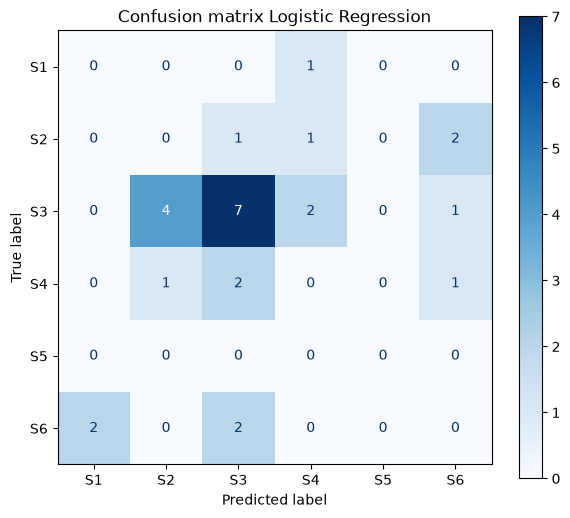

In [52]:
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Controleer het gekozen model
print("Gekozen model Logistic Regression:")
print(beste_logR)

# Maak voorspellingen op de testset
y_pred = beste_logR.predict(X_test)

# Bereken de evaluatiemetrics
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

accuracy = accuracy_score(y_test, y_pred)

# Toon de resultaten
print("\nDefinitieve evaluatie Logistic Regression")
print("========================================")
print(f"Macro F1-score:    {macro_f1:.3f}")
print(f"Weighted F1-score: {weighted_f1:.3f}")
print(f"Accuracy:          {accuracy:.3f}")


# Classification report
print("\nClassification report:")
print("======================")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[1, 2, 3, 4, 5, 6],
        target_names=["S1", "S2", "S3", "S4", "S5", "S6"],
        zero_division=0
    )
)


# Confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[1, 2, 3, 4, 5, 6],
    display_labels=["S1", "S2", "S3", "S4", "S5", "S6"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Confusion matrix Logistic Regression")

plt.show()

Mijn gekozen Logistic Regression-model behaalt op de testset een macro F1-score van 0,09, een weighted F1-score van 0,28 en een accuracy van 0,26.

De macro F1-score is aanzienlijk lager dan de eerder gevonden validatiescore. Dit laat zien dat de prestaties tijdens het hyperparameteronderzoek niet goed overeenkomen met de prestaties op de ongeziene testdata. Mogelijk heb ik mijn hyperparameters te sterk afgestemd op dezelfde twee validatiefolds, waardoor overfitting op de validatieprocedure is ontstaan. Ik kan dit op basis van deze resultaten alleen niet met zekerheid vaststellen.

Ook de kleine dataset kan een grote invloed hebben gehad op de resultaten. Zo bevatte mijn trainingsset slechts twee observaties van klasse S5, terwijl deze klasse helemaal niet voorkomt in de testset. Hierdoor kan ik de prestaties van het model op S5 niet beoordelen.

In het classificatie report zie ik dat alleen klasse S = 3 correct wordt voorspeld. Van de 14 observaties uit deze klasse worden er 7 goed geclassificeerd. De overige klassen worden niet correct voorspeld.

De confusion matrix bevestigt dit beeld. Het model verwart onder andere observaties uit S = 3 met S = 2 en S = 4. Ook worden de observaties uit S = 6 als S = 1 of S = 3 voorspeld. Het model heeft dus moeite om de verschillende klassen van elkaar te onderscheiden.

Met slechts 27 testobservaties en een ongelijke klasseverdeling is mijn evaluatie beperkt. Eén verkeerde voorspelling kan bij de kleinere klassen al een grote invloed hebben op de resultaten.

## Conclusie

Uit de definitieve evaluatie blijkt dat Logistic Regression op de testset aanzienlijk lager scoort dan tijdens cross-validation. Het model voorspelt slechts ** *7 van de 27 observaties correct* **, en deze behoren allemaal tot klasse S = 3.

Hiermee kan ik niet concluderen dat mijn gekozen model goed generaliseert naar nieuwe data. De hogere validatiescore uit Deel F blijkt geen goede voorspelling te zijn van de prestaties op deze testset. De combinatie van een kleine dataset, een ongelijke klasseverdeling en het uitgebreide hyperparameteronderzoek op slechts twee validatiefolds kan hieraan hebben bijgedragen. De overfitting gaat natuur;lijk snel op een kleine dataset. dus ik denk ook dat de te diepe zoom op hoogste f1 score tijdens cross validatie er voor heeft gezorgd dat het model overfit is.

Hoewel Logistic Regression tijdens de modelvergelijking de hoogste validatiescore behaalde, laten de testresultaten zien dat deze modelkeuze niet automatisch leidt tot goede prestaties op ongeziene data.

voor een andere keer, zou ik mijn model minder complex trainen en meer globaliseren. dit zal waarschijnlijk een iets hogere f1 score lijden maar nogsteeds laag uitvallen. Het is gewoon een rot dataset! Maar de oefening was leuk en interresant.

Ik wil ook nog even kwijt dat ik hier echt veel uur in heb zitten en dat de uitkomst mij dan ook wel behoorlijk teleursteld. Desalniettemin heb ik veel geleerd van deze opdracht en ben ik benieuwd naar de stappen die ik beter had kunnen ondernemen binnen modelkeuze. Ik zie graag feedback tegemoet.
